DOWNLOAD DATASET FROM KAGGLE

In [26]:
from pathlib import Path
import zipfile
import urllib.request

def download_kaggle_dataset(url):
    tarball_path = Path("datasets/loan_approval_dataset.zip")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, tarball_path)
    with zipfile.ZipFile(tarball_path, 'r') as loan_approval_zip:
            loan_approval_zip.extractall(path="datasets")

download_kaggle_dataset("https://www.kaggle.com/api/v1/datasets/download/architsharma01/loan-approval-prediction-dataset")

IMPORT THE DATASET FILE

In [27]:
import pandas as pd
df = pd.read_csv('datasets/loan_approval_dataset.csv')

RECORD THE ENVIRONMENT (`for reproducibility`)

In [28]:
import platform, sys
import numpy as np, scipy, sklearn, matplotlib

print(f"Python {platform.python_version()} on {platform.platform()}")
for module in (pd, np, scipy, sklearn, matplotlib):
    print(f"{module.__name__} {module.__version__}")

Python 3.11.16 on macOS-26.3-arm64-arm-64bit
pandas 2.1.4
numpy 1.26.4
scipy 1.11.4
sklearn 1.3.2
matplotlib 3.8.4


CLEAN THE DATA (`attribute and observations contains trailing whitespaces`)

In [29]:
# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

# Remove leading and trailing spaces from string values in the DataFrame
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

# Inspect null values in the DataFrame
print(df.isnull().sum())

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64


INSPECT AND UNDERSTAND THE DATASET

In [30]:
# Dataset Shape
r, c = df.shape
print(f"The dataset has {c} attributes and {r} observations.")

# Dataset Information
df.info()

The dataset has 13 attributes and 4269 observations.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
m

UNDERSTAND THE VALUES RANGE

array([[<Axes: title={'center': 'no_of_dependents'}>,
        <Axes: title={'center': 'income_annum'}>,
        <Axes: title={'center': 'loan_amount'}>],
       [<Axes: title={'center': 'loan_term'}>,
        <Axes: title={'center': 'cibil_score'}>,
        <Axes: title={'center': 'residential_assets_value'}>],
       [<Axes: title={'center': 'commercial_assets_value'}>,
        <Axes: title={'center': 'luxury_assets_value'}>,
        <Axes: title={'center': 'bank_asset_value'}>]], dtype=object)

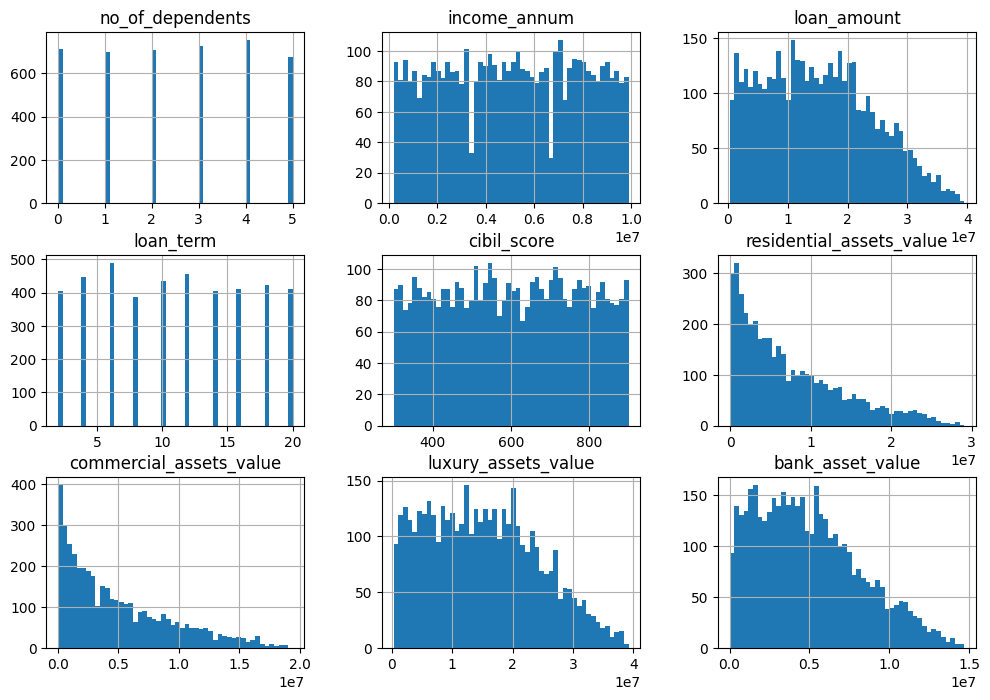

In [31]:
# drop the Loan ID column as it is not useful for prediction
df = df.drop('loan_id', axis=1)

df.hist(bins=50, figsize=(12, 8))


The target variable `loan_status` is either `Approved` or `Rejected`. Hence, this is a `binary classification` task.

In [32]:
#  CONVERT LABEL TO NUMERIC (BINARY)
df['loan_status'] = df['loan_status'].map({ 'Approved': 1, 'Rejected': 0 })

# .map() turns unexpected values into NaN, so fail loudly if that happens
assert df['loan_status'].notna().all(), "Unexpected value found in loan_status"

df.head(5)

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0


EXPLORATORY DATA ANALYSIS (`distributions, data-quality checks and relationships with loan_status`)

In [33]:
import numpy as np
import matplotlib.pyplot as plt

print(df.describe().T.round(2))

# Data-quality checks
numeric = df.select_dtypes("number")
negatives = (numeric < 0).sum()
print("\nNegative values per numeric column:")
print(negatives[negatives > 0] if (negatives > 0).any() else "none")
print(f"Duplicated rows: {df.duplicated().sum()}")

# Approval rate by categorical attribute
for col in ["education", "self_employed"]:
    print(f"\nApproval rate by {col}:")
    print(df.groupby(col)["loan_status"].agg(approval_rate="mean", n="count").round(3))

# Approval rate by CIBIL score band, and around a score of 550
bands = pd.cut(df["cibil_score"], bins=[299, 449, 549, 649, 749, 900])
print("\nApproval rate by CIBIL score band:")
print(df.groupby(bands, observed=True)["loan_status"].agg(approval_rate="mean", n="count").round(3))
print("\nApproval rate below / at-or-above a CIBIL score of 550:")
print(df.groupby(df["cibil_score"] >= 550)["loan_status"].agg(approval_rate="mean", n="count").round(3))

                           count         mean         std       min  \
no_of_dependents          4269.0         2.50        1.70       0.0   
income_annum              4269.0   5059123.92  2806839.83  200000.0   
loan_amount               4269.0  15133450.46  9043362.98  300000.0   
loan_term                 4269.0        10.90        5.71       2.0   
cibil_score               4269.0       599.94      172.43     300.0   
residential_assets_value  4269.0   7472616.54  6503636.59 -100000.0   
commercial_assets_value   4269.0   4973155.31  4388966.09       0.0   
luxury_assets_value       4269.0  15126305.93  9103753.67  300000.0   
bank_asset_value          4269.0   4976692.43  3250185.31       0.0   
loan_status               4269.0         0.62        0.48       0.0   

                                25%         50%         75%         max  
no_of_dependents                1.0         3.0         4.0         5.0  
income_annum              2700000.0   5100000.0   7500000.0   9900000.

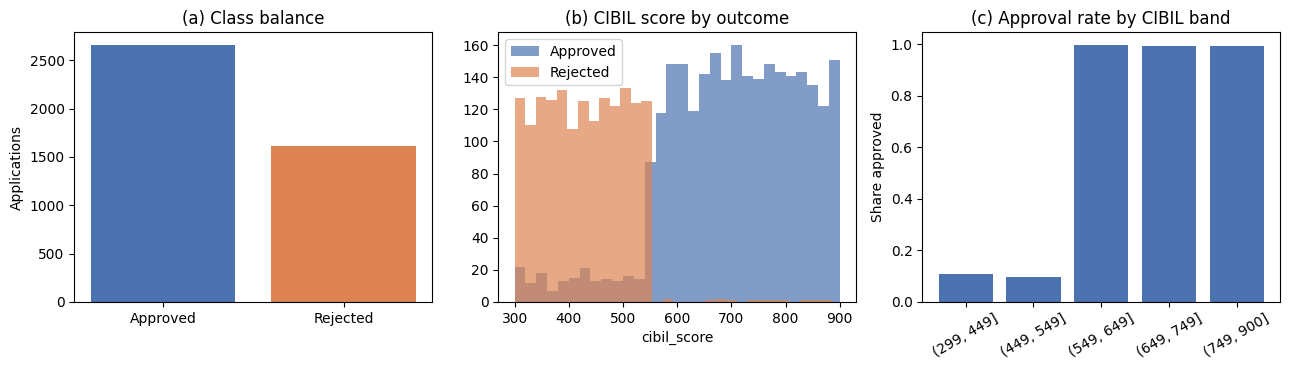

In [34]:
from pathlib import Path

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

# (a) class balance
counts = df["loan_status"].map({1: "Approved", 0: "Rejected"}).value_counts()
axes[0].bar(counts.index, counts.values, color=["#4C72B0", "#DD8452"])
axes[0].set_title("(a) Class balance")
axes[0].set_ylabel("Applications")

# (b) cibil_score by outcome
axes[1].hist(df.loc[df["loan_status"] == 1, "cibil_score"], bins=30, alpha=0.7, label="Approved", color="#4C72B0")
axes[1].hist(df.loc[df["loan_status"] == 0, "cibil_score"], bins=30, alpha=0.7, label="Rejected", color="#DD8452")
axes[1].set_title("(b) CIBIL score by outcome")
axes[1].set_xlabel("cibil_score")
axes[1].legend()

# (c) approval rate by CIBIL band
band_rate = df.groupby(bands, observed=True)["loan_status"].mean()
axes[2].bar([str(b) for b in band_rate.index], band_rate.values, color="#4C72B0")
axes[2].set_title("(c) Approval rate by CIBIL band")
axes[2].set_ylabel("Share approved")
axes[2].tick_params(axis="x", rotation=30)

fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/eda_overview.png", dpi=300)
plt.show()

INSPECT FEATURE CORRELATIONS (`Pearson correlation of each numeric attribute with loan_status; no attributes are removed`)

In [35]:
corr_matrix = df.corr(numeric_only=True)
print(corr_matrix["loan_status"].sort_values(ascending=False))

#cibil_score is the most correlated with loan_status

# checking the distribution of the target variable (loan_status)
print(df['loan_status'].value_counts())

# loan_status is imbalanced, with more approved loans than rejected loans.

loan_status                 1.000000
cibil_score                 0.770518
loan_amount                 0.016150
commercial_assets_value     0.008246
bank_asset_value           -0.006778
residential_assets_value   -0.014367
income_annum               -0.015189
luxury_assets_value        -0.015465
no_of_dependents           -0.018114
loan_term                  -0.113036
Name: loan_status, dtype: float64
loan_status
1    2656
0    1613
Name: count, dtype: int64


CREATING STRATIFIED SHUFFLED SPLIT

In [36]:
from sklearn.model_selection import train_test_split

# Stratifying using loan_status to preserve equal proportion of approved and rejected loans in both training and testing sets
strat_train_set, strat_test_set = train_test_split(
    df,
    test_size=0.2,
    stratify=df["loan_status"],
    random_state=42
)

PREPROCESSING THE TRAINING DATA

In [37]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

train_set = strat_train_set.drop("loan_status", axis=1)
train_set_labels = strat_train_set["loan_status"].copy()

categorical_cols = train_set.select_dtypes(include=["object", "string"]).columns.tolist()
numerical_cols = train_set.select_dtypes(include=["int64", "float64"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), categorical_cols),
        ("num", "passthrough", numerical_cols)
    ]
)

DETERMINE THE BEST CLASSIFIER ALGORITHM USING `RANDOMIZED` SEARCH

In [38]:
# Define the general cross-validation strategy
from sklearn.model_selection import StratifiedKFold

cross_validation_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

MAJORITY-CLASS BASELINE (`a model that always predicts the most frequent class; any useful model must beat it`)

In [39]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])
baseline.fit(train_set, train_set_labels)

baseline_cv_f1 = cross_val_score(baseline, train_set, train_set_labels, cv=cross_validation_strategy, scoring="f1")
print(f"Majority-class baseline, mean 5-fold CV F1 on the training set: {baseline_cv_f1.mean():.4f}")
print(f"Share of the majority class (Approved) in the training set: {train_set_labels.mean():.4f}")

Majority-class baseline, mean 5-fold CV F1 on the training set: 0.7671
Share of the majority class (Approved) in the training set: 0.6223


TRAIN AND EVALUATE A `LOGISTIC REGRESSION` CLASSIFIER

In [40]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from scipy.stats import loguniform

# Logistic regression is sensitive to feature scale (incomes are in the millions, cibil_score in the hundreds), so scale after preprocessing
logistic_regression_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_regression_param_distribs = {
    "classifier__C": loguniform(1e-3, 1e2),
    "classifier__class_weight": [None, "balanced"]
}

logistic_regression_search = RandomizedSearchCV(
    logistic_regression_pipeline,
    param_distributions=logistic_regression_param_distribs,
    n_iter=50,
    cv=cross_validation_strategy,
    scoring="f1", # Using F1 score for balance between precision and recall
    random_state=42,
    n_jobs=-1
)

logistic_regression_search.fit(
    train_set,
    train_set_labels
)

# Display the best parameters:
print(logistic_regression_search.best_params_)

# Display the best F1 score achieved during the search:
print(f"Best F1 score achieved during the search: {logistic_regression_search.best_score_:.4f}")

{'classifier__C': 0.008263688714158009, 'classifier__class_weight': 'balanced'}
Best F1 score achieved during the search: 0.9330


TRAIN AND EVALUATE A `DECISION TREE CLASSIFIER`

In [41]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

decision_tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

decision_tree_param_distribs = {
    "classifier__max_depth": randint(
        low=1,
        high=21
    ),
    "classifier__min_samples_split": randint(
        low=2,
        high=21
    )
}

decision_tree_search = RandomizedSearchCV(
    estimator= decision_tree_pipeline, 
    param_distributions=decision_tree_param_distribs,
    n_iter=50,
    cv=cross_validation_strategy,
    scoring="f1", # Using F1 score for balance between precision and recall
    random_state=42,
    n_jobs=-1
)

decision_tree_search.fit(
    train_set,
    train_set_labels
)

# Display the best parameters:
print(decision_tree_search.best_params_)

# Display the best F1 score achieved during the search:
print(f"Best F1 score achieved during the search: {decision_tree_search.best_score_:.4f}")


{'classifier__max_depth': 16, 'classifier__min_samples_split': 16}
Best F1 score achieved during the search: 0.9830


TRAIN AND EVALUATE A `RANDOM FOREST CLASSIFIER`

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint


random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

random_forest_param_distribs = {
    "classifier__n_estimators": randint(
        low=20,
        high=301
    ),
    "classifier__max_features": randint(
        low=1,
        high=12  # 11 features after encoding, so max_features can reach all of them
    )
}

random_forest_search = RandomizedSearchCV(
    random_forest_pipeline,
    param_distributions=random_forest_param_distribs,
    n_iter=50,
    cv=cross_validation_strategy,
    scoring="f1", # Using F1 score for balance between precision and recall
    random_state=42,
    n_jobs=-1
)

random_forest_search.fit(
    train_set,
    train_set_labels
)

# Display the best parameters:
print(random_forest_search.best_params_)

# Display the best F1 score achieved during the search:
print(f"Best F1 score achieved during the search: {random_forest_search.best_score_:.4f}")


EVALUATE THE `LOGISTIC-REGRESSION`, `DECISION-TREE` AND `RANDOM-FOREST` BEST ESTIMATORS ON THE TEST SET

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score

test_set = strat_test_set.drop("loan_status", axis=1)
test_set_labels = strat_test_set["loan_status"].copy()

models = {
    "Logistic Regression": logistic_regression_search.best_estimator_,
    "Decision Tree": decision_tree_search.best_estimator_,
    "Random Forest": random_forest_search.best_estimator_,
}

rows = []
for name, model in models.items():
    predictions = model.predict(test_set)
    probabilities = model.predict_proba(test_set)[:, 1]

    rows.append({
        "Model": name,
        "F1": f1_score(test_set_labels, predictions),
        "Precision": precision_score(test_set_labels, predictions),
        "Recall": recall_score(test_set_labels, predictions),
        "ROC AUC": roc_auc_score(test_set_labels, probabilities),
    })

baseline_pred = baseline.predict(test_set)
rows.append({
    "Model": "Majority-class baseline",
    "F1": f1_score(test_set_labels, baseline_pred),
    "Precision": precision_score(test_set_labels, baseline_pred),
    "Recall": recall_score(test_set_labels, baseline_pred),
    "ROC AUC": roc_auc_score(test_set_labels, baseline.predict_proba(test_set)[:, 1]),
})

model_comparison = pd.DataFrame(rows)
model_comparison

,Model,F1,Precision,Recall,ROC AUC
0,Logistic Regression,0.944606,0.975904,0.915254,0.973839
1,Decision Tree,0.985019,0.979516,0.990584,0.989065
2,Random Forest,0.991565,0.986940,0.996234,0.998685
3,Majority-class baseline,0.766787,0.621780,1.000000,0.500000


PLOT THE CONFUSION MATRICES

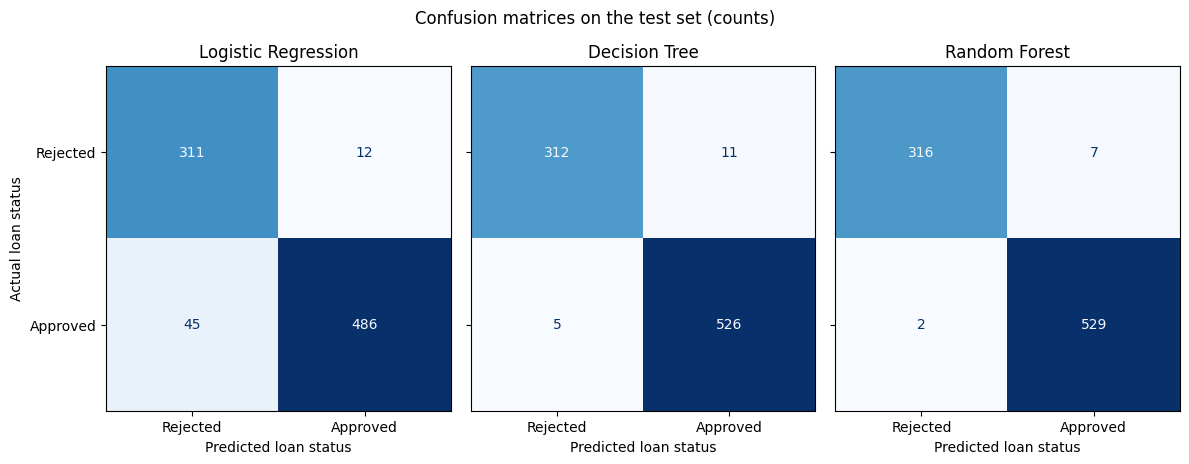

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# One panel per model (each panel has its own colour scale; read the counts in the cells)
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 4.5), sharey=True)

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        test_set_labels,
        model.predict(test_set),
        display_labels=["Rejected", "Approved"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted loan status")
    ax.set_ylabel("Actual loan status" if ax is axes[0] else "")
    ax.grid(False)

fig.suptitle("Confusion matrices on the test set (counts)")
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/confusion_matrices.png", dpi=300)
plt.show()

ERROR COSTS: FALSE APPROVALS VS FALSE REJECTIONS (`a false approval is a loan granted to an applicant who should have been rejected`)

In [ ]:
# Confusion-matrix counts as text, plus false-approval and false-rejection rates.
# Class 1 = Approved, so FP = false approval and FN = false rejection.
rows = []
for name, model in {**models, "Majority-class baseline": baseline}.items():
    tn, fp, fn, tp = confusion_matrix(test_set_labels, model.predict(test_set)).ravel()
    rows.append({
        "Model": name, "TN": tn, "FP (false approvals)": fp, "FN (false rejections)": fn, "TP": tp,
        "False approval rate": fp / (fp + tn), "False rejection rate": fn / (fn + tp),
    })
error_table = pd.DataFrame(rows)
error_table

,Model,TN,FP (false approvals),FN (false rejections),TP,False approval rate,False rejection rate
0,Logistic Regression,311,12,45,486,0.037152,0.084746
1,Decision Tree,312,11,5,526,0.034056,0.009416
2,Random Forest,316,7,2,529,0.021672,0.003766
3,Majority-class baseline,0,323,0,531,1.000000,0.000000


In [ ]:
# Illustrative cost-sensitive threshold. ASSUMPTION: a false approval costs 5 times a false rejection.
# This ratio is NOT taken from real lending data; it only shows how the decision threshold shifts when errors are weighted.
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

COST_FALSE_APPROVAL, COST_FALSE_REJECTION = 5, 1
best_name = model_comparison.sort_values("F1", ascending=False).iloc[0]["Model"]
best_model = models[best_name]

# Choose the threshold on out-of-fold training predictions only, so the test set stays untouched
oof_proba = cross_val_predict(clone(best_model), train_set, train_set_labels,
                              cv=cross_validation_strategy, method="predict_proba")[:, 1]

def mean_cost(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    fp = ((pred == 1) & (y_true == 0)).sum()
    fn = ((pred == 0) & (y_true == 1)).sum()
    return (COST_FALSE_APPROVAL * fp + COST_FALSE_REJECTION * fn) / len(y_true), fp, fn

thresholds = np.arange(0.05, 0.96, 0.05)
oof_costs = [mean_cost(train_set_labels.values, oof_proba, t)[0] for t in thresholds]
best_threshold = thresholds[int(np.argmin(oof_costs))]

test_proba = best_model.predict_proba(test_set)[:, 1]
for label, t in [("default 0.50", 0.5), (f"cost-tuned {best_threshold:.2f}", best_threshold)]:
    cost, fp, fn = mean_cost(test_set_labels.values, test_proba, t)
    print(f"{best_name}, threshold {label}: false approvals={fp}, false rejections={fn}, mean cost per applicant={cost:.3f}")

Random Forest, threshold default 0.50: false approvals=7, false rejections=2, mean cost per applicant=0.043
Random Forest, threshold cost-tuned 0.75: false approvals=6, false rejections=14, mean cost per applicant=0.052


STABILITY: REPEATED CROSS-VALIDATION AND MULTIPLE TRAIN/TEST SPLITS (`the tuned hyperparameters are fixed; only the data partition changes`)

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

# (a) 5-fold CV repeated 10 times on the training set (50 F1 scores per model)
repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
rows = []
for name, model in {**models, "Majority-class baseline": baseline}.items():
    scores = cross_val_score(clone(model), train_set, train_set_labels, cv=repeated_cv, scoring="f1", n_jobs=-1)
    rows.append({"Model": name, "Mean CV F1": scores.mean(), "Std": scores.std(), "Min": scores.min(), "Max": scores.max()})
repeated_cv_table = pd.DataFrame(rows)
repeated_cv_table

,Model,Mean CV F1,Std,Min,Max
0,Logistic Regression,0.931912,9.641548e-03,0.907960,0.955260
1,Decision Tree,0.979234,5.649210e-03,0.966981,0.990544
2,Random Forest,0.986314,3.649758e-03,0.978035,0.994125
3,Majority-class baseline,0.767148,1.110223e-16,0.767148,0.767148


In [ ]:
# (b) Ten different stratified 80/20 splits (seeds 0-9) with the hyperparameters found above held fixed.
# CAVEAT: those hyperparameters were tuned on the seed-42 training set, so test rows of other seeds can overlap
# the tuning data; treat this as a measure of split-to-split variation, not as an unbiased generalisation estimate.
X_all = df.drop("loan_status", axis=1)
y_all = df["loan_status"]
rows = []
for seed in range(10):
    X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=seed)
    for name, model in models.items():
        fitted = clone(model).fit(X_tr, y_tr)
        rows.append({"Seed": seed, "Model": name, "F1": f1_score(y_te, fitted.predict(X_te)),
                     "ROC AUC": roc_auc_score(y_te, fitted.predict_proba(X_te)[:, 1])})
multi_split = pd.DataFrame(rows).groupby("Model")[["F1", "ROC AUC"]].agg(["mean", "std"])
multi_split

F1             ROC AUC          
                         mean       std      mean       std
Model                                                      
Decision Tree        0.981055  0.004728  0.983929  0.004506
Logistic Regression  0.938984  0.008732  0.968932  0.005311
Random Forest        0.987052  0.002048  0.997082  0.002283

EXPLAINABILITY: PERMUTATION FEATURE IMPORTANCE (`which original attributes does the best model rely on?`)

Permutation importance for the Random Forest model (test set, 30 repeats):
                     feature  mean_drop_in_f1     std
0                cibil_score           0.3430  0.0131
1                  loan_term           0.0416  0.0042
2                loan_amount           0.0162  0.0018
3               income_annum           0.0146  0.0023
4        luxury_assets_value           0.0057  0.0015
5    commercial_assets_value           0.0035  0.0013
6           no_of_dependents           0.0014  0.0009
7   residential_assets_value           0.0011  0.0010
8           bank_asset_value           0.0005  0.0007
9                  education           0.0000  0.0000
10             self_employed           0.0000  0.0000


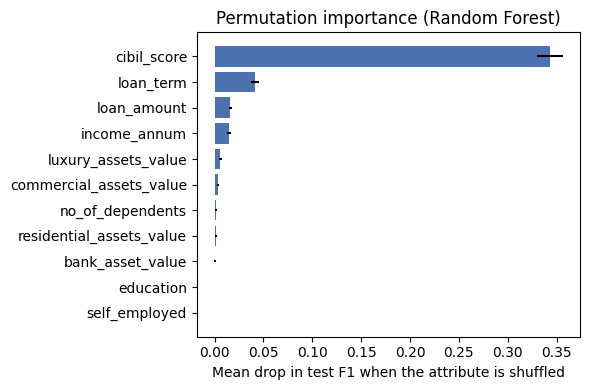

In [ ]:
from sklearn.inspection import permutation_importance

# Permutation importance on the held-out test set: the drop in F1 when one original attribute is shuffled.
# The pipeline is passed as a whole, so each attribute is shuffled before one-hot encoding.
perm = permutation_importance(best_model, test_set, test_set_labels, scoring="f1",
                              n_repeats=30, random_state=42, n_jobs=-1)
importance = (pd.DataFrame({"feature": test_set.columns, "mean_drop_in_f1": perm.importances_mean, "std": perm.importances_std})
              .sort_values("mean_drop_in_f1", ascending=False).reset_index(drop=True))
print(f"Permutation importance for the {best_name} model (test set, 30 repeats):")
print(importance.round(4))

Path("figures").mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(6, 4))
top = importance.iloc[::-1]
ax.barh(top["feature"], top["mean_drop_in_f1"], xerr=top["std"], color="#4C72B0")
ax.set_xlabel("Mean drop in test F1 when the attribute is shuffled")
ax.set_title(f"Permutation importance ({best_name})")
fig.tight_layout()
fig.savefig("figures/permutation_importance.png", dpi=300)
plt.show()

FAIRNESS CHECK ACROSS APPLICANT GROUPS (`education and self_employed are the only group-like attributes; the dataset has no protected attributes such as gender, age or ethnicity`)

In [ ]:
# Group-wise behaviour of the best model on the test set (a screening check, not a fairness audit).
# Selection rate = share predicted Approved; TPR = share of truly approved applicants who are approved;
# FPR = share of truly rejected applicants who are (wrongly) approved.
pred = best_model.predict(test_set)
rows = []
for col in ["education", "self_employed"]:
    for group, idx in test_set.groupby(col).groups.items():
        y_t = test_set_labels.loc[idx]
        y_p = pd.Series(pred, index=test_set.index).loc[idx]
        rows.append({
            "Attribute": col, "Group": group, "n": len(idx),
            "Actual approval rate": y_t.mean(), "Selection rate": y_p.mean(),
            "TPR": ((y_p == 1) & (y_t == 1)).sum() / (y_t == 1).sum(),
            "FPR": ((y_p == 1) & (y_t == 0)).sum() / (y_t == 0).sum(),
        })
group_table = pd.DataFrame(rows)
print(group_table.round(3).to_string(index=False))
for col in ["education", "self_employed"]:
    sub = group_table[group_table["Attribute"] == col]
    print(f"{col}: selection-rate gap = {sub['Selection rate'].max() - sub['Selection rate'].min():.3f}, "
          f"TPR gap = {sub['TPR'].max() - sub['TPR'].min():.3f}, FPR gap = {sub['FPR'].max() - sub['FPR'].min():.3f}")

    Attribute        Group   n  Actual approval rate  Selection rate   TPR   FPR
    education     Graduate 434                 0.622           0.627 0.996 0.018
    education Not Graduate 420                 0.621           0.629 0.996 0.025
self_employed           No 426                 0.636           0.641 0.996 0.019
self_employed          Yes 428                 0.607           0.614 0.996 0.024
education: selection-rate gap = 0.002, TPR gap = 0.000, FPR gap = 0.007
self_employed: selection-rate gap = 0.026, TPR gap = 0.000, FPR gap = 0.004
